# Esteira de aprendizado de máquina: triagem de risco de diabetes

**Autora:** Alice
**Disciplina:** Inteligência Artificial (FATEC Praia Grande, ADS)
**Tipo de problema:** classificação binária

Neste notebook eu construo uma esteira completa de aprendizado de máquina, da preparação dos dados até a predição com o modelo salvo. A base é a *Pima Indians Diabetes Database* e o objetivo é prever, a partir de exames e medidas simples (glicose, pressão, IMC, idade etc.), se a paciente **tem diabetes** (1) ou **não** (0).

## Mapa do notebook

| Seção | O que acontece | Requisito do trabalho |
|---|---|---|
| 1 | Escolha e carga da base | 1 e 2 |
| 2 | Estatísticas descritivas | 3 |
| 3 | Transformações nas colunas | 4 |
| 4 | Transformações nas linhas | 5 |
| 5 | Divisão em treino, validação e teste | 6 |
| 6 | Treino e comparação de modelos (validação) | 7 |
| 7 | Avaliação final: matriz de confusão e acurácia (teste) | 7 e 8 |
| 8 | Implantação do modelo e predição de novas pacientes | 9 |
| 9 | Limitações e cuidados | extra |

In [133]:
import platform
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Semente fixa: quem rodar de novo obtém exatamente os mesmos conjuntos e resultados.
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.12.10 | pandas 3.1.1 | scikit-learn 1.9.1


## 1. Escolha e carga da base de dados

**Base:** *Pima Indians Diabetes Database*
**Link (Kaggle):** https://www.kaggle.com/datasets/rishabhm76/pima-diabetes-database
**Origem dos dados:** National Institute of Diabetes and Digestive and Kidney Diseases (EUA), disponibilizada pelo repositório UCI Machine Learning.
**Tamanho:** 768 pacientes, 8 colunas de entrada e a coluna alvo `Outcome`. Todas são mulheres com pelo menos 21 anos, de origem Pima.

**Problema:** dado um conjunto de medidas simples, estimar se a paciente tem diabetes. É um problema clássico de triagem em saúde: um modelo assim poderia ajudar a priorizar quem deve fazer exames mais completos.

**Por que escolhi:** saúde é uma das áreas onde aprendizado de máquina tem mais impacto, e o IMC (obesidade) é um dos fatores centrais da base. A base também tem problemas reais de qualidade de dados (zeros que na verdade são valores faltantes), o que torna as etapas de transformação bem justificadas.

**Variável alvo (`Outcome`):** `1` = tem diabetes, `0` = não tem.

### Dicionário de dados

| Coluna | Descrição |
|---|---|
| `Pregnancies` | Número de gestações |
| `Glucose` | Glicose no teste oral de tolerância (mg/dL) |
| `BloodPressure` | Pressão arterial diastólica (mm Hg) |
| `SkinThickness` | Espessura da dobra cutânea do tríceps (mm) |
| `Insulin` | Insulina sérica de 2 horas (mu U/ml) |
| `BMI` | Índice de massa corporal (peso em kg / altura em m ao quadrado) |
| `DiabetesPedigreeFunction` | Pontuação de histórico familiar de diabetes |
| `Age` | Idade em anos |
| `Outcome` | Alvo: 1 = tem diabetes, 0 = não tem |

### Como a base é carregada

A célula abaixo usa `data/diabetes.csv` (arquivo do Kaggle) se ele existir. Se não existir, baixa automaticamente a mesma base de um espelho público no GitHub (o arquivo original não tem cabeçalho, então os nomes das colunas são aplicados aqui) e salva uma cópia em `data/diabetes.csv`.

In [134]:
COLUNAS = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
    "BMI", "DiabetesPedigreeFunction", "Age", "Outcome",
]
CSV_LOCAL = Path("data/diabetes.csv")
URL_ESPELHO = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"

if CSV_LOCAL.exists():
    origem = f"arquivo local {CSV_LOCAL}"
    df_original = pd.read_csv(CSV_LOCAL)
else:
    try:
        df_original = pd.read_csv(URL_ESPELHO, header=None, names=COLUNAS)
        CSV_LOCAL.parent.mkdir(exist_ok=True)
        df_original.to_csv(CSV_LOCAL, index=False)
        origem = f"download do espelho no GitHub (cópia salva em {CSV_LOCAL})"
    except Exception as erro:
        raise RuntimeError(
            "Não consegui obter a base. Opções: (a) confira sua conexão e rode de novo; "
            "(b) baixe o diabetes.csv no Kaggle (link acima) e coloque dentro da pasta data/. "
            "Veja o README.md."
        ) from erro

faltando = set(COLUNAS) - set(df_original.columns)
assert not faltando, f"Colunas esperadas que não existem no arquivo: {faltando}"
df_original = df_original[COLUNAS]

df = df_original.copy()  # trabalho sempre em cópias, o original fica intacto

print(f"Fonte dos dados: {origem}")
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
df.head()

Fonte dos dados: arquivo local data\diabetes.csv
Linhas: 768 | Colunas: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [135]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## 2. Estatísticas descritivas gerais

In [136]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


,pacientes,%
Outcome,,
0 (sem diabetes),500,65.1
1 (com diabetes),268,34.9


Linhas duplicadas: 0
Valores nulos (NaN): 0


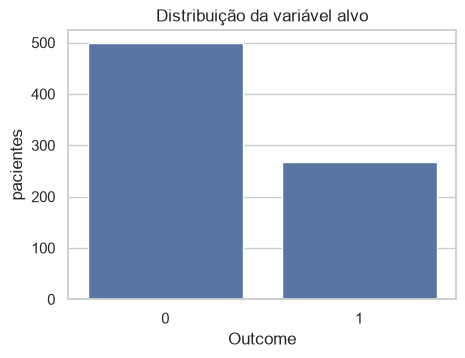

In [137]:
distribuicao = df["Outcome"].value_counts().rename({0: "0 (sem diabetes)", 1: "1 (com diabetes)"})
percentual = (df["Outcome"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"pacientes": distribuicao, "%": percentual.values}))

print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Valores nulos (NaN): {int(df.isna().sum().sum())}")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Outcome", ax=ax)
ax.set_title("Distribuição da variável alvo")
ax.set_xlabel("Outcome")
ax.set_ylabel("pacientes")
plt.show()

**Leitura:** a classe `1` é menos frequente que a `0`. A base é moderadamente **desbalanceada**, então a acurácia sozinha engana: um modelo que sempre responde "sem diabetes" já acertaria a maioria dos casos. Por isso vou comparar com esse baseline e olhar também precisão, recall e F1 da classe 1.

### Um problema escondido: zeros impossíveis

A tabela de estatísticas mostra `min = 0` em glicose, pressão, dobra cutânea, insulina e IMC. Uma pessoa viva não tem pressão arterial ou IMC igual a zero, então esses zeros são **valores faltantes disfarçados**. O `NaN` não aparece porque a base original usou 0 para "não medido".

In [138]:
COLUNAS_ZERO_IMPOSSIVEL = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zeros = pd.DataFrame({
    "zeros": (df[COLUNAS_ZERO_IMPOSSIVEL] == 0).sum(),
    "% da base": ((df[COLUNAS_ZERO_IMPOSSIVEL] == 0).mean() * 100).round(1),
})
zeros

,zeros,% da base
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


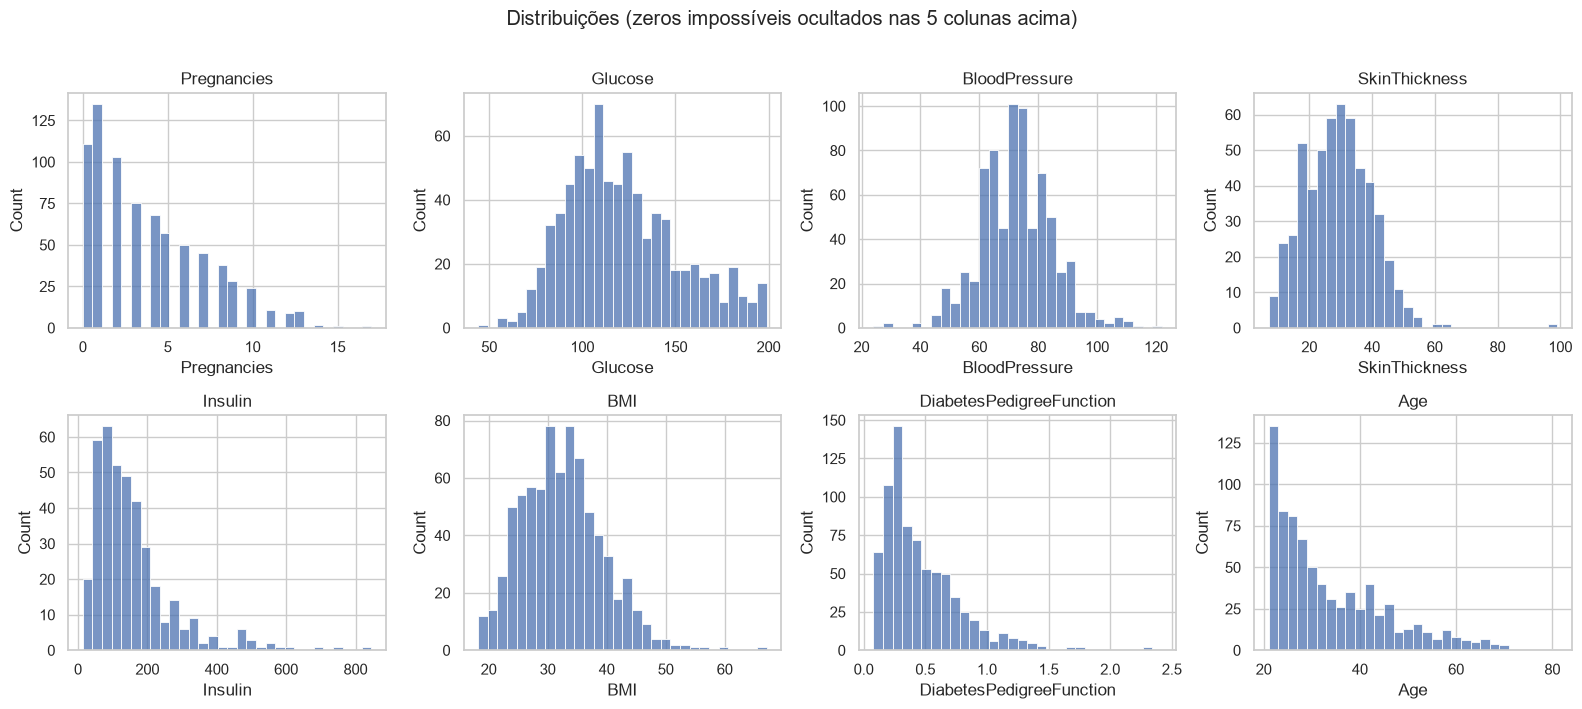

In [139]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, coluna in zip(axes.ravel(), df.columns.drop("Outcome")):
    sns.histplot(data=df[df[coluna] > 0] if coluna in COLUNAS_ZERO_IMPOSSIVEL else df, x=coluna, bins=30, ax=ax)
    ax.set_title(coluna)
plt.suptitle("Distribuições (zeros impossíveis ocultados nas 5 colunas acima)", y=1.01)
plt.tight_layout()
plt.show()

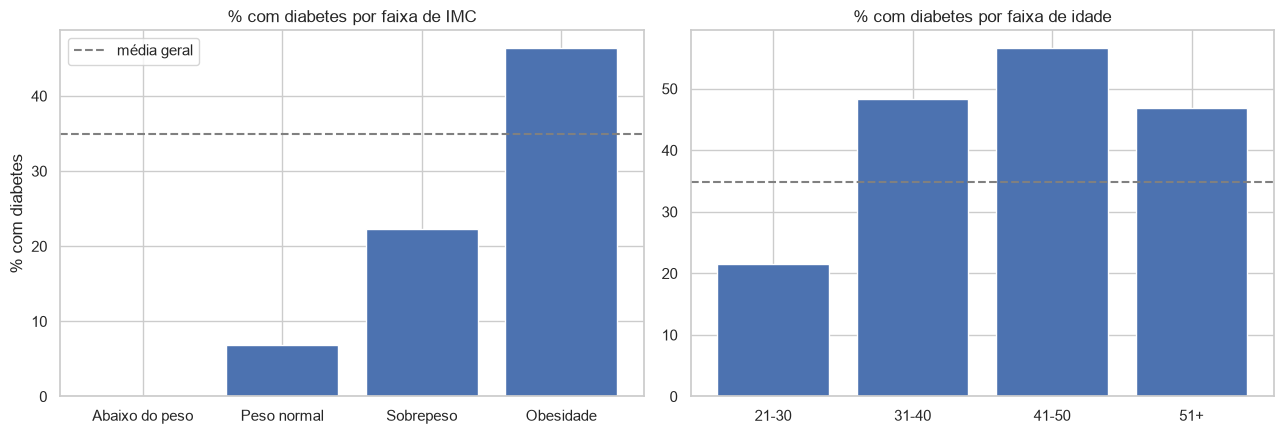

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

faixa = pd.cut(
    df["BMI"].where(df["BMI"] > 0),
    bins=[0, 18.5, 25, 30, np.inf],
    labels=["Abaixo do peso", "Peso normal", "Sobrepeso", "Obesidade"],
    right=False,
)
taxa_imc = df.groupby(faixa, observed=True)["Outcome"].mean() * 100
axes[0].bar(taxa_imc.index.astype(str), taxa_imc.values)
axes[0].axhline(df["Outcome"].mean() * 100, color="gray", linestyle="--", label="média geral")
axes[0].set_title("% com diabetes por faixa de IMC")
axes[0].set_ylabel("% com diabetes")
axes[0].legend()

faixa_idade = pd.cut(df["Age"], bins=[20, 30, 40, 50, 100], labels=["21-30", "31-40", "41-50", "51+"])
taxa_idade = df.groupby(faixa_idade, observed=True)["Outcome"].mean() * 100
axes[1].bar(taxa_idade.index.astype(str), taxa_idade.values)
axes[1].axhline(df["Outcome"].mean() * 100, color="gray", linestyle="--")
axes[1].set_title("% com diabetes por faixa de idade")

plt.tight_layout()
plt.show()

**Leitura:** a proporção de diabetes muda bastante entre as faixas (a linha tracejada é a média geral). O gráfico da esquerda mostra a relação entre obesidade e diabetes na própria base, e é um dos motivos de eu ter criado uma coluna de faixa de IMC na próxima seção.

## 3. Transformações nas colunas

Decisões desta etapa, todas sem aprender nada a partir dos dados (por isso podem ser feitas antes da divisão):

1. **Trocar os zeros impossíveis por valor faltante (`NaN`)** em glicose, pressão, dobra cutânea, insulina e IMC. Sem isso, o modelo trataria "não medido" como "valor zero".
2. **Aplicar `log(1 + x)` em `DiabetesPedigreeFunction`:** a distribuição tem cauda longa para a direita, e o log aproxima de algo mais comportado.
3. **Criar `faixa_imc`** a partir do IMC, com as faixas da OMS: abaixo do peso (menor que 18,5), peso normal (18,5 a 24,9), sobrepeso (25 a 29,9) e obesidade (30 ou mais). Mantenho também o IMC numérico.
4. **Remover `SkinThickness`:** tem muitos valores faltantes e uma correlação alta com o IMC, então traz pouca informação nova (a correlação é mostrada abaixo).

Os passos que **aprendem** com os dados (preencher valores faltantes, padronizar escala e codificar categorias) ficam dentro da esteira do scikit-learn e só são ajustados com o conjunto de treino, para não vazar informação de validação e teste.

In [141]:
COLUNAS_NUMERICAS = [
    "Pregnancies", "Glucose", "BloodPressure", "Insulin", "BMI",
    "DiabetesPedigreeFunction_log", "Age",
]
COLUNAS_CATEGORICAS = ["faixa_imc"]


def preparar_colunas(dados):
    """Transformações de coluna sem estado. A mesma função é usada na predição de novas pacientes."""
    dados = dados.copy()

    for coluna in COLUNAS_ZERO_IMPOSSIVEL:
        dados[coluna] = dados[coluna].replace(0, np.nan)

    dados["DiabetesPedigreeFunction_log"] = np.log1p(dados["DiabetesPedigreeFunction"])

    dados["faixa_imc"] = pd.cut(
        dados["BMI"],
        bins=[0, 18.5, 25, 30, np.inf],
        labels=["Abaixo do peso", "Peso normal", "Sobrepeso", "Obesidade"],
        right=False,
    ).astype(object)

    return dados.drop(columns=["SkinThickness", "DiabetesPedigreeFunction"], errors="ignore")


# Justificativa do item 4: correlação da dobra cutânea com o IMC (com zeros já tratados como faltantes)
df_zeros_tratados = df.copy()
for coluna in COLUNAS_ZERO_IMPOSSIVEL:
    df_zeros_tratados[coluna] = df_zeros_tratados[coluna].replace(0, np.nan)
corr_pele_imc = df_zeros_tratados["SkinThickness"].corr(df_zeros_tratados["BMI"])
print(f"SkinThickness: {df_zeros_tratados['SkinThickness'].isna().mean() * 100:.1f}% faltante | "
      f"correlação com BMI: {corr_pele_imc:.2f}")

df_col = preparar_colunas(df)

print(f"\nColunas antes: {df.shape[1]} | depois: {df_col.shape[1]}")
print("Colunas finais:", list(df_col.columns))
df_col.head(8)

SkinThickness: 29.6% faltante | correlação com BMI: 0.65

Colunas antes: 9 | depois: 9
Colunas finais: ['Pregnancies', 'Glucose', 'BloodPressure', 'Insulin', 'BMI', 'Age', 'Outcome', 'DiabetesPedigreeFunction_log', 'faixa_imc']


,Pregnancies,Glucose,BloodPressure,Insulin,BMI,Age,Outcome,DiabetesPedigreeFunction_log,faixa_imc
0,6,148.0,72.0,NaN,33.6,50,1,0.486738,Obesidade
1,1,85.0,66.0,NaN,26.6,31,0,0.300845,Sobrepeso
2,8,183.0,64.0,NaN,23.3,32,1,0.514021,Peso normal
3,1,89.0,66.0,94.0,28.1,21,0,0.154436,Sobrepeso
4,0,137.0,40.0,168.0,43.1,33,1,1.190279,Obesidade
5,5,116.0,74.0,NaN,25.6,30,0,0.183155,Sobrepeso
6,3,78.0,50.0,88.0,31.0,26,1,0.221542,Obesidade
7,10,115.0,NaN,NaN,35.3,29,0,0.125751,Obesidade


In [ ]:
print("Valores faltantes depois de tratar os zeros:")
display(pd.DataFrame({
    "faltantes": df_col.isna().sum(),
    "% da base": (df_col.isna().mean() * 100).round(1),
}).query("faltantes > 0"))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df_col[COLUNAS_NUMERICAS + ["Outcome"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação entre colunas numéricas")
plt.show()

## 4. Transformações nas linhas

Duas regras de limpeza:

1. **Remover linhas duplicadas:** registros idênticos contam duas vezes e podem aparecer no treino e no teste ao mesmo tempo, o que infla o resultado. A checagem usa as colunas originais.
2. **Remover linhas sem glicose, pressão ou IMC:** são medidas básicas e poucas pacientes não têm. Prefiro não inventar (imputar) essas medidas, e a quantidade removida é pequena. `Insulin` **não** entra nessa regra porque falta em quase metade da base, e remover todas essas linhas jogaria fora muitos dados. Ela será preenchida dentro da esteira.

Antes de remover, confiro quantas linhas saem e se a remoção distorce a proporção da classe alvo.

In [142]:
mask_duplicadas = df.duplicated(keep="first")
mask_sem_medida_basica = df_col[["Glucose", "BloodPressure", "BMI"]].isna().any(axis=1)
remover = mask_duplicadas | mask_sem_medida_basica

print(f"Linhas duplicadas: {mask_duplicadas.sum()}")
print(f"Linhas sem glicose, pressão ou IMC: {mask_sem_medida_basica.sum()}")
print(f"Total removido: {remover.sum()} ({remover.mean() * 100:.2f}% da base)")
print(f"Proporção da classe 1 na base toda: {df['Outcome'].mean() * 100:.1f}%")
print(f"Proporção da classe 1 nas linhas removidas: {df.loc[remover, 'Outcome'].mean() * 100:.1f}%")

df_final = df_col.loc[~remover].reset_index(drop=True)
print(f"\nBase final: {df_final.shape[0]} linhas x {df_final.shape[1]} colunas")
print(f"Proporção da classe 1 na base final: {df_final['Outcome'].mean() * 100:.1f}%")

Linhas duplicadas: 0
Linhas sem glicose, pressão ou IMC: 44
Total removido: 44 (5.73% da base)
Proporção da classe 1 na base toda: 34.9%
Proporção da classe 1 nas linhas removidas: 43.2%

Base final: 724 linhas x 9 colunas
Proporção da classe 1 na base final: 34.4%


**Como interpretar:** compare a proporção da classe 1 nas linhas removidas com a da base toda. Se for parecida, a limpeza não distorce o problema. Não há duplicadas nesta base, então a regra 1 não remove nada, mas deixo registrada porque é uma verificação padrão antes de dividir os dados.

## 5. Divisão em treino, validação e teste

Divisão **70% / 15% / 15%**, estratificada pela classe alvo (cada subconjunto mantém a mesma proporção de 0 e 1):

- **Treino:** o modelo aprende aqui.
- **Validação:** uso para comparar modelos e ajustar hiperparâmetros.
- **Teste:** fica guardado e só é usado **uma vez**, no final, para medir o desempenho real.

A base é pequena, então validação e teste ficam com poucas pacientes. Por isso, no final, também calculo um intervalo de confiança para a acurácia (seção 7).

In [143]:
X = df_final.drop(columns="Outcome")
y = df_final["Outcome"].astype(int)

# 1) separa 15% para teste
X_resto, X_teste, y_resto, y_teste = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED
)
# 2) do que sobrou, separa validação (15% do total = 0,15/0,85 do que restou)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_resto, y_resto, test_size=0.15 / 0.85, stratify=y_resto, random_state=SEED
)

resumo_split = pd.DataFrame({
    "conjunto": ["Treino", "Validação", "Teste"],
    "linhas": [len(X_treino), len(X_val), len(X_teste)],
    "% do total": [len(X_treino) / len(X) * 100, len(X_val) / len(X) * 100, len(X_teste) / len(X) * 100],
    "% classe 1": [y_treino.mean() * 100, y_val.mean() * 100, y_teste.mean() * 100],
}).round(2)
resumo_split

,conjunto,linhas,% do total,% classe 1
0,Treino,506,69.89,34.39
1,Validação,109,15.06,34.86
2,Teste,109,15.06,33.94


## 6. Treinamento e comparação de modelos

### Pré-processamento dentro da esteira

O `ColumnTransformer` aplica, **ajustado só no treino**:

- **Numéricas:** preenche faltantes com a mediana (e cria uma coluna indicando que o valor estava faltando, porque "insulina não medida" pode ser informativo) e padroniza a escala (média 0, desvio 1).
- **Categóricas (`faixa_imc`):** preenche faltantes com `"Desconhecido"` e aplica one-hot encoding.

### Modelos comparados (na validação)

- **Baseline:** sempre prevê a classe majoritária. Serve de piso: o modelo precisa vencer isso.
- **Regressão Logística:** simples e interpretável.
- **Random Forest:** captura relações não lineares.
- **Gradient Boosting:** costuma ir bem em dados tabulares.

Como a base é desbalanceada, uso `class_weight` nos modelos que aceitam e escolho o melhor pelo **F1 da classe 1**, sem esquecer a acurácia.

In [144]:
def criar_preprocessador():
    numericas = Pipeline([
        ("imputador", SimpleImputer(strategy="median", add_indicator=True)),
        ("escala", StandardScaler()),
    ])
    categoricas = Pipeline([
        ("imputador", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numericas, COLUNAS_NUMERICAS),
        ("cat", categoricas, COLUNAS_CATEGORICAS),
    ])


def montar_pipeline(classificador):
    return Pipeline([("prep", criar_preprocessador()), ("clf", classificador)])


# Demonstração: o pré-processador aprende só com o treino
prep_demo = criar_preprocessador().fit(X_treino)
print(f"Treino antes: {X_treino.shape[1]} colunas | depois do pré-processamento: {prep_demo.transform(X_treino).shape[1]} colunas")

Treino antes: 8 colunas | depois do pré-processamento: 12 colunas


In [145]:
def avaliar(pipe, X_av, y_av):
    pred = pipe.predict(X_av)
    proba = pipe.predict_proba(X_av)[:, 1]
    return {
        "Acurácia": accuracy_score(y_av, pred),
        "Precisão (1)": precision_score(y_av, pred, zero_division=0),
        "Recall (1)": recall_score(y_av, pred, zero_division=0),
        "F1 (1)": f1_score(y_av, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_av, proba),
    }


modelos = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

pipelines = {}
linhas = {}
for nome, clf in modelos.items():
    pipe = montar_pipeline(clf).fit(X_treino, y_treino)
    pipelines[nome] = pipe
    linhas[nome] = avaliar(pipe, X_val, y_val)

pd.DataFrame(linhas).T.round(4)

,Acurácia,Precisão (1),Recall (1),F1 (1),ROC AUC
Baseline (classe majoritária),0.6514,0.0000,0.0000,0.0000,0.5000
Regressão Logística,0.7798,0.6522,0.7895,0.7143,0.8821
Random Forest,0.8073,0.7179,0.7368,0.7273,0.8940
Gradient Boosting,0.8349,0.8125,0.6842,0.7429,0.8732


### Ajuste simples de hiperparâmetros (Random Forest)

Uso o conjunto de **validação** para testar algumas combinações de profundidade máxima e tamanho mínimo da folha. O teste continua intocado.

In [146]:
busca = []
melhor_f1, melhor_rf = -1, None
for prof in [None, 4, 8]:
    for folha in [1, 3, 5]:
        rf = RandomForestClassifier(
            n_estimators=300, max_depth=prof, min_samples_leaf=folha,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
        )
        pipe = montar_pipeline(rf).fit(X_treino, y_treino)
        m = avaliar(pipe, X_val, y_val)
        busca.append({"max_depth": prof, "min_samples_leaf": folha, **m})
        if m["F1 (1)"] > melhor_f1:
            melhor_f1, melhor_rf = m["F1 (1)"], pipe

tabela_busca = pd.DataFrame(busca).sort_values("F1 (1)", ascending=False).round(4)
display(tabela_busca)

pipelines["Random Forest (ajustado)"] = melhor_rf
linhas["Random Forest (ajustado)"] = avaliar(melhor_rf, X_val, y_val)

,max_depth,min_samples_leaf,Acurácia,Precisão (1),Recall (1),F1 (1),ROC AUC
0,NaN,1,0.8349,0.7941,0.7105,0.7500,0.8944
1,NaN,3,0.8073,0.7179,0.7368,0.7273,0.8940
2,NaN,5,0.7982,0.7000,0.7368,0.7179,0.8962
4,4.0,3,0.7890,0.6744,0.7632,0.7160,0.9033
8,8.0,5,0.7798,0.6591,0.7632,0.7073,0.8988
5,4.0,5,0.7706,0.6444,0.7632,0.6988,0.9066
6,8.0,1,0.7798,0.6750,0.7105,0.6923,0.8962
7,8.0,3,0.7706,0.6512,0.7368,0.6914,0.8940
3,4.0,1,0.7615,0.6364,0.7368,0.6829,0.9033


In [147]:
tabela_validacao = pd.DataFrame(linhas).T.round(4).sort_values("F1 (1)", ascending=False)
display(tabela_validacao)

candidatos = tabela_validacao.drop(index="Baseline (classe majoritária)")
nome_final = candidatos["F1 (1)"].idxmax()
modelo_final = pipelines[nome_final]
print(f"Modelo escolhido pelo F1 na validação: {nome_final}")

,Acurácia,Precisão (1),Recall (1),F1 (1),ROC AUC
Random Forest (ajustado),0.8349,0.7941,0.7105,0.7500,0.8944
Gradient Boosting,0.8349,0.8125,0.6842,0.7429,0.8732
Random Forest,0.8073,0.7179,0.7368,0.7273,0.8940
Regressão Logística,0.7798,0.6522,0.7895,0.7143,0.8821
Baseline (classe majoritária),0.6514,0.0000,0.0000,0.0000,0.5000


Modelo escolhido pelo F1 na validação: Random Forest (ajustado)


**Atenção:** a validação tem poucas pacientes, então diferenças pequenas entre os modelos são ruído, não vantagem real. Escolho pelo F1 mesmo assim, por ser um critério claro, mas não devo concluir que o modelo vencedor é muito melhor que os outros.

### Quais colunas mais pesam na decisão?

Importância por permutação, medida na **validação**: embaralho uma coluna por vez e vejo quanto o F1 cai. Quanto maior a queda, mais o modelo depende daquela coluna.

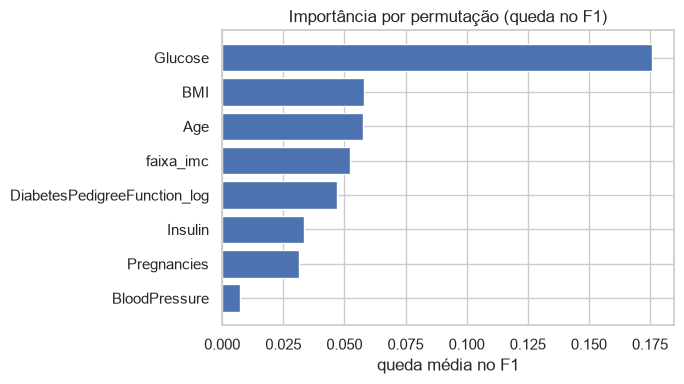

In [148]:
imp = permutation_importance(
    modelo_final, X_val, y_val, scoring="f1", n_repeats=20, random_state=SEED, n_jobs=-1
)
importancias = pd.Series(imp.importances_mean, index=X_val.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importancias.index, importancias.values)
ax.set_title("Importância por permutação (queda no F1)")
ax.set_xlabel("queda média no F1")
plt.tight_layout()
plt.show()

## 7. Avaliação final no conjunto de teste

Agora o modelo escolhido é avaliado **uma única vez** no teste, que ele nunca viu nem influenciou nenhuma decisão.

In [149]:
pred_teste = modelo_final.predict(X_teste)
proba_teste = modelo_final.predict_proba(X_teste)[:, 1]

acuracia_teste = accuracy_score(y_teste, pred_teste)
acuracia_baseline = max(y_teste.mean(), 1 - y_teste.mean())

print(f"Modelo: {nome_final}")
print(f"Acurácia no teste: {acuracia_teste:.4f} ({acuracia_teste * 100:.2f}%)")
print(f"Acurácia do baseline (sempre a classe majoritária): {acuracia_baseline:.4f} ({acuracia_baseline * 100:.2f}%)")
print()
print(classification_report(y_teste, pred_teste, target_names=["0 (sem diabetes)", "1 (com diabetes)"], digits=3))

Modelo: Random Forest (ajustado)
Acurácia no teste: 0.7156 (71.56%)
Acurácia do baseline (sempre a classe majoritária): 0.6606 (66.06%)

                  precision    recall  f1-score   support

0 (sem diabetes)      0.773     0.806     0.789        72
1 (com diabetes)      0.588     0.541     0.563        37

        accuracy                          0.716       109
       macro avg      0.681     0.673     0.676       109
    weighted avg      0.711     0.716     0.712       109



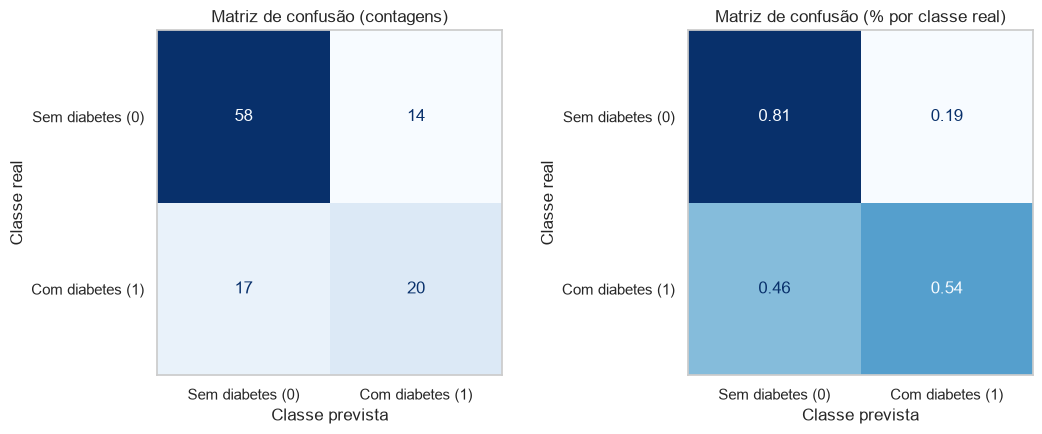

Verdadeiros negativos: 58  (sem diabetes e o modelo acertou)
Falsos positivos:      14  (sem diabetes, mas o modelo disse que tinha)
Falsos negativos:      17  (com diabetes, mas o modelo disse que não)
Verdadeiros positivos: 20  (com diabetes e o modelo acertou)


In [150]:
cm = confusion_matrix(y_teste, pred_teste)
rotulos = ["Sem diabetes (0)", "Com diabetes (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=rotulos).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Matriz de confusão (contagens)")
ConfusionMatrixDisplay(confusion_matrix(y_teste, pred_teste, normalize="true"), display_labels=rotulos).plot(
    ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False
)
axes[1].set_title("Matriz de confusão (% por classe real)")
for ax in axes:
    ax.grid(False)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
plt.tight_layout()

Path("figuras").mkdir(exist_ok=True)
fig.savefig("figuras/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Verdadeiros negativos: {tn}  (sem diabetes e o modelo acertou)")
print(f"Falsos positivos:      {fp}  (sem diabetes, mas o modelo disse que tinha)")
print(f"Falsos negativos:      {fn}  (com diabetes, mas o modelo disse que não)")
print(f"Verdadeiros positivos: {tp}  (com diabetes e o modelo acertou)")

**Como ler:** a diagonal principal (verdadeiros negativos e verdadeiros positivos) são os acertos. Em triagem de saúde, o **falso negativo** é o erro mais grave: uma paciente com diabetes que o modelo mandou para casa sem investigar. O falso positivo é um alarme falso, que leva a um exame a mais.

### Quão confiável é essa acurácia?

Como o teste tem poucas pacientes, a acurácia varia bastante de uma amostra para outra. Estimo um intervalo de confiança de 95% por *bootstrap*: sorteio, com reposição, 2000 amostras das predições do teste e vejo em que faixa a acurácia fica.

In [151]:
rng = np.random.default_rng(SEED)
acertos = (np.asarray(pred_teste) == np.asarray(y_teste)).astype(int)
medias = [rng.choice(acertos, size=len(acertos), replace=True).mean() for _ in range(2000)]
ic_baixo, ic_alto = np.percentile(medias, [2.5, 97.5])

print(f"Acurácia no teste: {acuracia_teste * 100:.1f}%")
print(f"Intervalo de confiança de 95%: de {ic_baixo * 100:.1f}% a {ic_alto * 100:.1f}% (teste com {len(y_teste)} pacientes)")

Acurácia no teste: 71.6%
Intervalo de confiança de 95%: de 63.3% a 79.8% (teste com 109 pacientes)


## 8. Implantação do modelo e predição

"Implantar" aqui significa salvar a esteira completa (pré-processamento + modelo) em um arquivo e carregá-la como se fosse outra aplicação, que recebe os dados brutos de uma paciente nova e devolve a predição.

In [152]:
Path("modelos").mkdir(exist_ok=True)
CAMINHO_MODELO = Path("modelos/modelo_final.joblib")

joblib.dump(modelo_final, CAMINHO_MODELO)
print(f"Modelo salvo em {CAMINHO_MODELO} ({CAMINHO_MODELO.stat().st_size / 1024:.0f} KB)")

# Simula outra aplicação: carrega do disco, sem usar o objeto que está em memória
modelo_implantado = joblib.load(CAMINHO_MODELO)

Modelo salvo em modelos\modelo_final.joblib (4579 KB)


In [153]:
def prever_paciente(dados_brutos, modelo=modelo_implantado, limiar=0.5):
    """Recebe uma paciente no formato original da base (0 = não medido) e devolve a predição."""
    df_novo = preparar_colunas(pd.DataFrame([dados_brutos]))
    df_novo = df_novo[COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS]
    prob = modelo.predict_proba(df_novo)[0, 1]
    return {
        "probabilidade de diabetes": round(float(prob), 3),
        "predição": "Com diabetes (1)" if prob >= limiar else "Sem diabetes (0)",
    }


paciente_a = {
    "Pregnancies": 1, "Glucose": 90, "BloodPressure": 68, "SkinThickness": 25, "Insulin": 0,
    "BMI": 22.5, "DiabetesPedigreeFunction": 0.2, "Age": 24,
}
paciente_b = {
    "Pregnancies": 6, "Glucose": 168, "BloodPressure": 82, "SkinThickness": 35, "Insulin": 200,
    "BMI": 36.5, "DiabetesPedigreeFunction": 0.9, "Age": 52,
}

resultado = pd.DataFrame(
    [prever_paciente(paciente_a), prever_paciente(paciente_b)],
    index=["Paciente A (24 anos, IMC 22,5, glicose 90)", "Paciente B (52 anos, IMC 36,5, glicose 168)"],
)
resultado

,probabilidade de diabetes,predição
"Paciente A (24 anos, IMC 22,5, glicose 90)",0.007,Sem diabetes (0)
"Paciente B (52 anos, IMC 36,5, glicose 168)",0.870,Com diabetes (1)


In [154]:
print("RESUMO PARA A APRESENTAÇÃO")
print(f"Base: {df_original.shape[0]} pacientes | usadas após limpeza: {df_final.shape[0]}")
print(f"Divisão: treino {len(X_treino)} | validação {len(X_val)} | teste {len(X_teste)}")
print(f"Modelo escolhido: {nome_final}")
print(f"Acurácia no teste: {acuracia_teste * 100:.2f}% (baseline: {acuracia_baseline * 100:.2f}%)")
print(f"Intervalo de confiança de 95% da acurácia: {ic_baixo * 100:.1f}% a {ic_alto * 100:.1f}%")
print(f"Precisão (1): {precision_score(y_teste, pred_teste, zero_division=0):.3f} | "
      f"Recall (1): {recall_score(y_teste, pred_teste, zero_division=0):.3f} | "
      f"F1 (1): {f1_score(y_teste, pred_teste, zero_division=0):.3f} | "
      f"ROC AUC: {roc_auc_score(y_teste, proba_teste):.3f}")

if acuracia_teste <= acuracia_baseline:
    print("\nAtenção: a acurácia ficou igual ou abaixo do baseline. Isso pode acontecer quando o modelo "
          "é calibrado para achar a classe minoritária (class_weight). Destaque recall, F1 e ROC AUC.")
else:
    print("\nA acurácia superou o baseline. Mesmo assim, olhe recall e F1 da classe 1, que mostram "
          "se o modelo realmente encontra quem tem diabetes.")

RESUMO PARA A APRESENTAÇÃO
Base: 768 pacientes | usadas após limpeza: 724
Divisão: treino 506 | validação 109 | teste 109
Modelo escolhido: Random Forest (ajustado)
Acurácia no teste: 71.56% (baseline: 66.06%)
Intervalo de confiança de 95% da acurácia: 63.3% a 79.8%
Precisão (1): 0.588 | Recall (1): 0.541 | F1 (1): 0.563 | ROC AUC: 0.765

A acurácia superou o baseline. Mesmo assim, olhe recall e F1 da classe 1, que mostram se o modelo realmente encontra quem tem diabetes.


## 9. Limitações e cuidados

- **Base pequena:** com cerca de 700 pacientes, validação e teste ficam com pouco mais de 100 cada. Os resultados oscilam bastante (veja o intervalo de confiança) e diferenças pequenas entre modelos são ruído.
- **População específica:** todas as pacientes são mulheres, com 21 anos ou mais, de origem Pima, nos Estados Unidos. O modelo não vale para homens, outras faixas de idade nem outras populações.
- **Zeros como faltantes:** tratei zeros impossíveis como faltantes, o que é a interpretação razoável, mas não é confirmada pelos autores da base. Insulina e dobra cutânea têm muita informação faltante.
- **Divisão única:** os resultados dependem de uma única separação treino/validação/teste. Validação cruzada daria uma estimativa mais estável.
- **Não é diagnóstico:** o modelo é um exercício acadêmico. Diabetes é diagnosticada por exames e profissionais de saúde, e este modelo não deve ser usado para decidir nada sobre uma pessoa real.
- **Implantação simplificada:** o modelo é salvo em arquivo e carregado localmente. Uma implantação de produção exigiria uma API, monitoramento e validação clínica.

### Próximos passos possíveis

Validação cruzada, ajuste do limiar de decisão para priorizar recall (reduzir falsos negativos), testar outros algoritmos e expor o modelo por uma API simples.